<a href="https://colab.research.google.com/github/luanoliveira-pixel/pcd_ei_iv_previsao_doencas_cardiacas/blob/main/pcd_doenca_cardiaca_knn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Previsão de Doença Cardíaca com KNN

Disciplina: Programação para Ciência de Dados

Integrantes: Gustavo Kulbaba, Luan de Oliveira e Victor Weizenmann

### Definição do problema

Doença cardíaca é uma das principais causas de morte no mundo, e muitos sinais aparecem em exames simples. O objetivo é prever, a partir desses exames, se o paciente tem ou não doença cardíaca. É uma classificação binária, resolvida com o KNN, usando a base Heart Disease da Cleveland Clinic (UCI), com 303 pacientes e 14 variáveis.

## 1. Importando as bibliotecas

O pandas manipula a tabela, o numpy faz cálculos com vetores, o matplotlib faz os gráficos e o scikit-learn cuida da divisão treino/teste, da padronização, do KNN e das métricas.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score   # separar treino/teste e validação cruzada
from sklearn.preprocessing import StandardScaler                        # padronizar as variáveis (mesma escala)
from sklearn.neighbors import KNeighborsClassifier                      # o algoritmo KNN para classificação
from sklearn.metrics import accuracy_score, recall_score, confusion_matrix, classification_report  # métricas de avaliação

## 2. Obtenção dos dados

O pd.read_csv lê o CSV direto do link e cria um DataFrame, onde cada linha é um paciente. O head() mostra as 5 primeiras linhas.

In [6]:
url = "https://raw.githubusercontent.com/luanoliveira-pixel/pcd_ei_iv_previsao_doencas_cardiacas/main/dados/heart.csv"
df = pd.read_csv(url)   # lê o CSV e guarda a tabela na variável df
df.head()               # mostra as 5 primeiras linhas

,Unnamed: 0,Age,Sex,ChestPain,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca,Thal,AHD
0,1,63,1,typical,145,233,1,2,150,0,2.3,3,0.0,fixed,No
1,2,67,1,asymptomatic,160,286,0,2,108,1,1.5,2,3.0,normal,Yes
2,3,67,1,asymptomatic,120,229,0,2,129,1,2.6,2,2.0,reversable,Yes
3,4,37,1,nonanginal,130,250,0,0,187,0,3.5,3,0.0,normal,No
4,5,41,0,nontypical,130,204,0,2,172,0,1.4,1,0.0,normal,No


O shape mostra linhas e colunas, e o info() mostra o tipo de cada coluna e quantos valores estão preenchidos. Ca e Thal têm menos de 303 valores, então há dados faltando.

In [7]:
print("Linhas e colunas:", df.shape)   # mostra (linhas, colunas)
df.info()                              # tipos das colunas e quantidade de valores preenchidos

Linhas e colunas: (303, 15)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 15 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  303 non-null    int64  
 1   Age         303 non-null    int64  
 2   Sex         303 non-null    int64  
 3   ChestPain   303 non-null    object 
 4   RestBP      303 non-null    int64  
 5   Chol        303 non-null    int64  
 6   Fbs         303 non-null    int64  
 7   RestECG     303 non-null    int64  
 8   MaxHR       303 non-null    int64  
 9   ExAng       303 non-null    int64  
 10  Oldpeak     303 non-null    float64
 11  Slope       303 non-null    int64  
 12  Ca          299 non-null    float64
 13  Thal        301 non-null    object 
 14  AHD         303 non-null    object 
dtypes: float64(2), int64(10), object(3)
memory usage: 35.6+ KB


## 3. Preparação e limpeza dos dados

### 3.1 Removendo a coluna de índice

A coluna Unnamed: 0 é só uma numeração do arquivo e não diz nada sobre o paciente. Se ficasse, atrapalharia o cálculo de distância do KNN.

In [8]:
df = df.drop(columns=["Unnamed: 0"])   # remove a coluna de índice e sobrescreve o df

### 3.2 Renomeando as colunas

O rename troca os nomes em inglês por nomes em português, usando um dicionário no formato {"antigo": "novo"}. O alvo é a coluna doenca: Yes tem doença, No não tem.

In [9]:
df = df.rename(columns={             # troca o nome das colunas usando um dicionário
    "Age": "idade",
    "Sex": "sexo",
    "ChestPain": "tipo_dor_peito",
    "RestBP": "pressao_repouso",
    "Chol": "colesterol",
    "Fbs": "glicemia_alta",
    "RestECG": "ecg_repouso",
    "MaxHR": "freq_cardiaca_max",
    "ExAng": "angina_exercicio",
    "Oldpeak": "depressao_st",
    "Slope": "inclinacao_st",
    "Ca": "num_vasos",
    "Thal": "talassemia",
    "AHD": "doenca"
})
df.head()                            # confere se os nomes mudaram

,idade,sexo,tipo_dor_peito,pressao_repouso,colesterol,glicemia_alta,ecg_repouso,freq_cardiaca_max,angina_exercicio,depressao_st,inclinacao_st,num_vasos,talassemia,doenca
0,63,1,typical,145,233,1,2,150,0,2.3,3,0.0,fixed,No
1,67,1,asymptomatic,160,286,0,2,108,1,1.5,2,3.0,normal,Yes
2,67,1,asymptomatic,120,229,0,2,129,1,2.6,2,2.0,reversable,Yes
3,37,1,nonanginal,130,250,0,0,187,0,3.5,3,0.0,normal,No
4,41,0,nontypical,130,204,0,2,172,0,1.4,1,0.0,normal,No


### 3.3 Valores faltando

O isnull() marca os valores vazios e o sum() conta quantos há em cada coluna.

In [10]:
df.isnull().sum()   # quantidade de valores vazios em cada coluna

,0
idade,0
sexo,0
tipo_dor_peito,0
pressao_repouso,0
colesterol,0
glicemia_alta,0
ecg_repouso,0
freq_cardiaca_max,0
angina_exercicio,0
depressao_st,0


São só 6 linhas com valor vazio (cerca de 2%), então removemos com dropna() em vez de inventar valores. O len(df) mostra o total antes e depois.

In [11]:
print("Linhas antes:", len(df))
df = df.dropna()
print("Linhas depois:", len(df))

Linhas antes: 303
Linhas depois: 297


### 3.4 Linhas duplicadas

O duplicated() marca linhas repetidas. Deu zero, então não há o que remover.

In [12]:
print("Linhas duplicadas:", df.duplicated().sum())

Linhas duplicadas: 0


### 3.5 Transformando o alvo em número

O map troca "No" por 0 e "Yes" por 1, porque o modelo só trabalha com números. São 160 sem doença e 137 com doença, classes equilibradas.

In [13]:
df["doenca"] = df["doenca"].map({"No": 0, "Yes": 1})   # texto -> número
df["doenca"].value_counts()                            # quantos 0 e quantos 1

,count
doenca,
0,160
1,137


## 4. Análise exploratória

O describe() mostra média, desvio, mínimo, quartis e máximo de cada coluna. Dá para ver que as escalas são bem diferentes (colesterol chega a 564, sexo vai de 0 a 1), o que importa para o KNN.

In [14]:
df.describe().round(1)   # estatísticas básicas, arredondadas

,idade,sexo,pressao_repouso,colesterol,glicemia_alta,ecg_repouso,freq_cardiaca_max,angina_exercicio,depressao_st,inclinacao_st,num_vasos,doenca
count,297.0,297.0,297.0,297.0,297.0,297.0,297.0,297.0,297.0,297.0,297.0,297.0
mean,54.5,0.7,131.7,247.4,0.1,1.0,149.6,0.3,1.1,1.6,0.7,0.5
std,9.0,0.5,17.8,52.0,0.4,1.0,22.9,0.5,1.2,0.6,0.9,0.5
min,29.0,0.0,94.0,126.0,0.0,0.0,71.0,0.0,0.0,1.0,0.0,0.0
25%,48.0,0.0,120.0,211.0,0.0,0.0,133.0,0.0,0.0,1.0,0.0,0.0
50%,56.0,1.0,130.0,243.0,0.0,1.0,153.0,0.0,0.8,2.0,0.0,0.0
75%,61.0,1.0,140.0,276.0,0.0,2.0,166.0,1.0,1.6,2.0,1.0,1.0
max,77.0,1.0,200.0,564.0,1.0,2.0,202.0,1.0,6.2,3.0,3.0,1.0


### 4.1 Pacientes por classe

O value_counts() conta os 0 e 1, e o plt.bar desenha as barras. As duas classes têm quantidades parecidas.

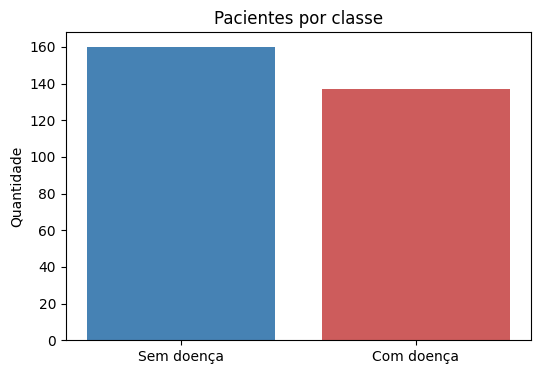

In [15]:
contagem = df["doenca"].value_counts().sort_index()

plt.figure(figsize=(6, 4))
plt.bar(["Sem doença", "Com doença"], contagem.values, color=["steelblue", "indianred"])
plt.title("Pacientes por classe")
plt.ylabel("Quantidade")
plt.show()

### 4.2 Idade e frequência cardíaca máxima por classe

O filtro df[df["doenca"] == 0] separa os pacientes por classe, e o plt.subplots cria dois gráficos lado a lado. O alpha deixa as cores transparentes para os histogramas se sobreporem.

Os doentes são um pouco mais velhos e atingem frequência máxima menor (139 contra 159 bpm).

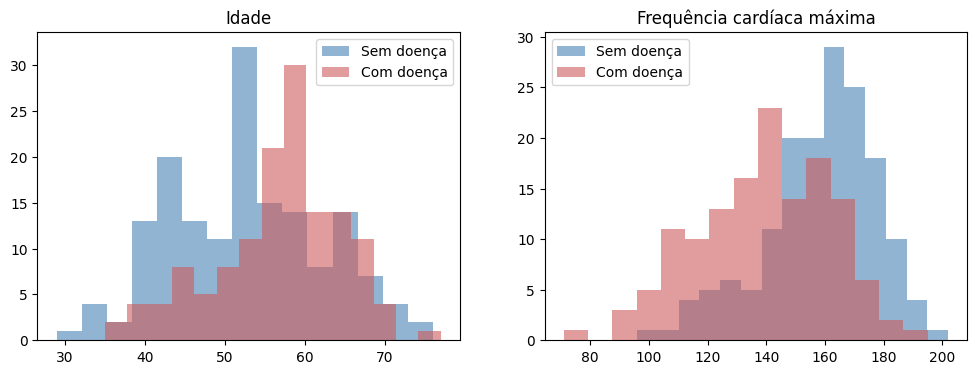

In [16]:
sem_doenca = df[df["doenca"] == 0]   # só os pacientes sem doença
com_doenca = df[df["doenca"] == 1]   # só os pacientes com doença

fig, eixos = plt.subplots(1, 2, figsize=(12, 4))   # 2 gráficos lado a lado

eixos[0].hist(sem_doenca["idade"], bins=15, alpha=0.6, color="steelblue", label="Sem doença")   # histograma dos saudáveis
eixos[0].hist(com_doenca["idade"], bins=15, alpha=0.6, color="indianred", label="Com doença")   # histograma dos doentes
eixos[0].set_title("Idade")    # título do gráfico da esquerda
eixos[0].legend()              # mostra a legenda (usa o label)

eixos[1].hist(sem_doenca["freq_cardiaca_max"], bins=15, alpha=0.6, color="steelblue", label="Sem doença")
eixos[1].hist(com_doenca["freq_cardiaca_max"], bins=15, alpha=0.6, color="indianred", label="Com doença")
eixos[1].set_title("Frequência cardíaca máxima")
eixos[1].legend()

plt.show()

### 4.3 Porcentagem de doentes por tipo de dor no peito

O groupby agrupa por tipo de dor e o mean() da coluna doença dá a proporção de doentes, já que ela é 0 ou 1.

O grupo "asymptomatic" tem 72,5% de doentes, bem acima dos outros. Ou seja, não sentir a dor típica não significa estar saudável.

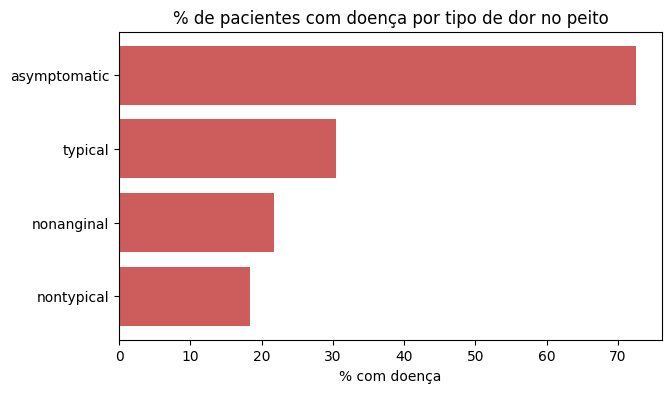

In [17]:
taxa_dor = df.groupby("tipo_dor_peito")["doenca"].mean() * 100   # % de doentes em cada tipo de dor
taxa_dor = taxa_dor.sort_values()                                 # ordena do menor para o maior

plt.figure(figsize=(7, 4))
plt.barh(taxa_dor.index, taxa_dor.values, color="indianred")   # barras horizontais (index = nomes, values = %)
plt.title("% de pacientes com doença por tipo de dor no peito")
plt.xlabel("% com doença")
plt.show()

### 4.4 Correlação com a doença

A correlação vai de -1 a 1 e mostra o quanto duas variáveis andam juntas. O corr() calcula para as colunas numéricas, e o np.where pinta de vermelho as positivas e de azul as negativas.

As mais fortes são num_vasos (0,46), depressao_st e angina_exercicio (0,42). A frequência máxima é negativa (-0,42), e o colesterol quase não tem relação (0,08).

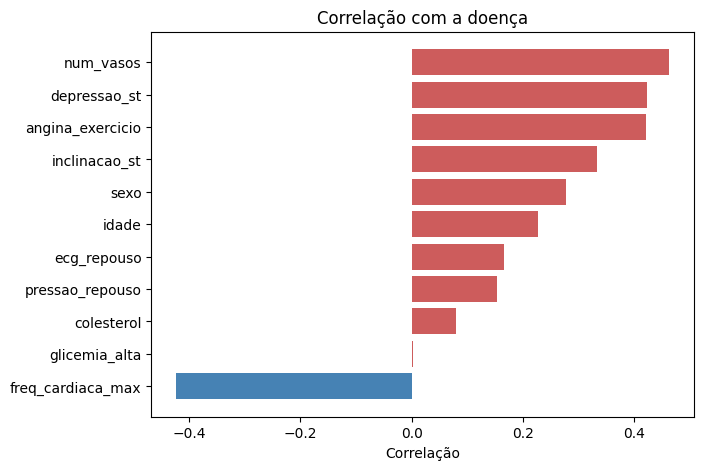

In [18]:
correlacao = df.select_dtypes(include="number").corr()["doenca"]   # correlação de cada coluna com a doença
correlacao = correlacao.drop("doenca").sort_values()               # tira a própria doença e ordena

cores = np.where(correlacao.values > 0, "indianred", "steelblue")  # vermelho se positiva, azul se negativa

plt.figure(figsize=(7, 5))
plt.barh(correlacao.index, correlacao.values, color=cores)
plt.title("Correlação com a doença")
plt.xlabel("Correlação")
plt.show()

### 4.5 Idade x frequência cardíaca máxima

No scatter, cada ponto é um paciente. Os doentes ficam mais embaixo e à direita, o que mostra a ideia do KNN: pacientes parecidos ficam perto uns dos outros.

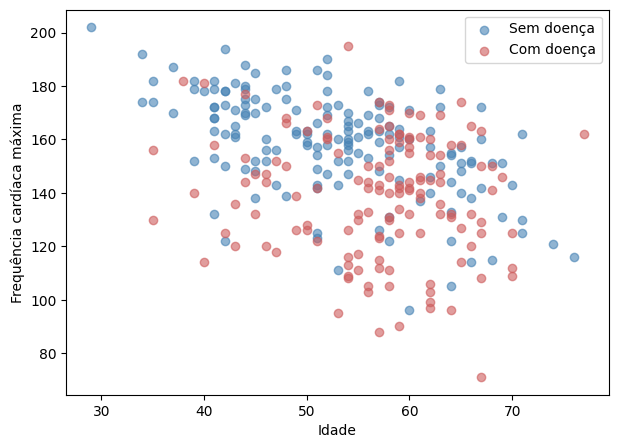

In [19]:
plt.figure(figsize=(7, 5))
plt.scatter(sem_doenca["idade"], sem_doenca["freq_cardiaca_max"], color="steelblue", alpha=0.6, label="Sem doença")   # pontos azuis
plt.scatter(com_doenca["idade"], com_doenca["freq_cardiaca_max"], color="indianred", alpha=0.6, label="Com doença")   # pontos vermelhos
plt.xlabel("Idade")
plt.ylabel("Frequência cardíaca máxima")
plt.legend()
plt.show()

## 5. Preparando os dados para o modelo

### 5.1 Transformando texto em colunas de 0 e 1 (one-hot encoding)

O get_dummies cria uma coluna de 0 e 1 para cada categoria de tipo_dor_peito e talassemia. Não usamos 1, 2, 3, 4 porque o modelo acharia que existe uma ordem entre elas.

In [20]:
df = pd.get_dummies(df, columns=["tipo_dor_peito", "talassemia"], dtype=int)   # texto -> várias colunas 0/1
df.head()

,idade,sexo,pressao_repouso,colesterol,glicemia_alta,ecg_repouso,freq_cardiaca_max,angina_exercicio,depressao_st,inclinacao_st,num_vasos,doenca,tipo_dor_peito_asymptomatic,tipo_dor_peito_nonanginal,tipo_dor_peito_nontypical,tipo_dor_peito_typical,talassemia_fixed,talassemia_normal,talassemia_reversable
0,63,1,145,233,1,2,150,0,2.3,3,0.0,0,0,0,0,1,1,0,0
1,67,1,160,286,0,2,108,1,1.5,2,3.0,1,1,0,0,0,0,1,0
2,67,1,120,229,0,2,129,1,2.6,2,2.0,1,1,0,0,0,0,0,1
3,37,1,130,250,0,0,187,0,3.5,3,0.0,0,0,1,0,0,0,1,0
4,41,0,130,204,0,2,172,0,1.4,1,0.0,0,0,0,1,0,0,1,0


### 5.2 Separando X, y, treino e teste

X são as variáveis de entrada e y é o alvo. O train_test_split separa 80% para treino e 20% para teste. O random_state=42 faz a divisão sair sempre igual, e o stratify=y mantém a mesma proporção de doentes nos dois conjuntos.

In [21]:
X = df.drop(columns=["doenca"])   # entradas: todas as colunas menos o alvo
y = df["doenca"]                  # saída: o alvo

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y   # 80/20, divisão reproduzível e proporcional
)

print("Treino:", X_treino.shape)   # (237, 18)
print("Teste:", X_teste.shape)     # (60, 18)

Treino: (237, 18)
Teste: (60, 18)


### 5.3 Padronização (StandardScaler)

O KNN usa distância, então variáveis com valores grandes dominariam as pequenas. O StandardScaler deixa cada coluna com média 0 e desvio 1.

O fit_transform aprende a média e o desvio só no treino e já transforma. No teste usamos apenas o transform, para não "espiar" dados que deveriam ser novos (vazamento de dados).

In [22]:
scaler = StandardScaler()                     # cria o padronizador
X_treino_pad = scaler.fit_transform(X_treino) # aprende média/desvio no treino e transforma o treino
X_teste_pad = scaler.transform(X_teste)       # transforma o teste com a média/desvio do treino

## 6. Escolhendo o melhor k (validação cruzada)

O KNN olha os k pacientes mais próximos e responde a classe que mais aparece entre eles. Um k muito pequeno erra por casos isolados (overfitting), e um k muito grande perde os detalhes (underfitting).

Testamos k ímpares de 1 a 29 (ímpar evita empate) com cross_val_score e cv=5: o treino é dividido em 5 partes, e a média das 5 notas é a nota de cada k. O teste não é usado nessa escolha. Também rodamos sem padronização, para comparar. O np.argmax pega a posição da maior acurácia.

In [23]:
valores_k = np.arange(1, 31, 2)   # k = 1, 3, 5, ..., 29
acuracias_com_pad = []            # notas usando dados padronizados
acuracias_sem_pad = []            # notas usando dados originais (para comparar)

for k in valores_k:                                  # testa cada valor de k
    knn = KNeighborsClassifier(n_neighbors=k)        # cria um KNN com k vizinhos

    notas = cross_val_score(knn, X_treino_pad, y_treino, cv=5, scoring="accuracy")   # 5 notas com dados padronizados
    acuracias_com_pad.append(notas.mean())                                           # guarda a média

    notas = cross_val_score(knn, X_treino, y_treino, cv=5, scoring="accuracy")       # 5 notas com dados sem padronizar
    acuracias_sem_pad.append(notas.mean())

melhor_k = valores_k[np.argmax(acuracias_com_pad)]   # k que teve a maior média
print("Melhor k:", melhor_k)
print("Acurácia média na validação:", round(max(acuracias_com_pad), 3))

Melhor k: 21
Acurácia média na validação: 0.822


### Gráfico da acurácia por k

Com padronização a acurácia fica perto de 82%, e sem ela perto de 65%. O k = 1 é o pior (72%), e a partir de k = 11 a curva estabiliza. O melhor foi k = 21, marcado pela linha tracejada.

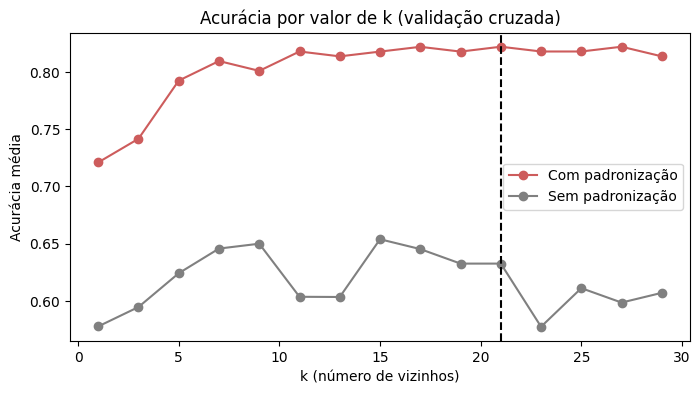

In [24]:
plt.figure(figsize=(8, 4))
plt.plot(valores_k, acuracias_com_pad, marker="o", color="indianred", label="Com padronização")   # curva padronizada
plt.plot(valores_k, acuracias_sem_pad, marker="o", color="gray", label="Sem padronização")       # curva sem padronizar
plt.axvline(melhor_k, linestyle="--", color="black")   # linha vertical no melhor k
plt.title("Acurácia por valor de k (validação cruzada)")
plt.xlabel("k (número de vizinhos)")
plt.ylabel("Acurácia média")
plt.legend()
plt.show()

## 7. Treinando o modelo final

O modelo é criado com o melhor k. No KNN, o fit só guarda os dados de treino, e o predict busca os 21 vizinhos mais próximos de cada paciente do teste para dar a resposta.

In [25]:
modelo = KNeighborsClassifier(n_neighbors=melhor_k)   # cria o modelo com o melhor k
modelo.fit(X_treino_pad, y_treino)                    # guarda os dados de treino

previsoes = modelo.predict(X_teste_pad)               # prevê a classe de cada paciente do teste

## 8. Avaliação no conjunto de teste

### Acurácia e recall

A acurácia é a porcentagem de acertos. O recall mostra quantos dos doentes de verdade o modelo encontrou, o que é importante em saúde porque deixar um doente passar é o erro mais grave.

In [26]:
acuracia = accuracy_score(y_teste, previsoes)   # % de acertos
recall = recall_score(y_teste, previsoes)       # % dos doentes que o modelo encontrou

print("Acurácia:", round(acuracia, 3))
print("Recall (doentes encontrados):", round(recall, 3))

Acurácia: 0.85
Recall (doentes encontrados): 0.786


### Matriz de confusão

As linhas são o valor real e as colunas o previsto. A diagonal são os acertos, e fora dela estão os falsos positivos (alarme falso) e os falsos negativos (doente classificado como saudável). Os dois for escrevem o número em cada célula com plt.text.

Foram 51 acertos, 3 falsos positivos e 6 falsos negativos.

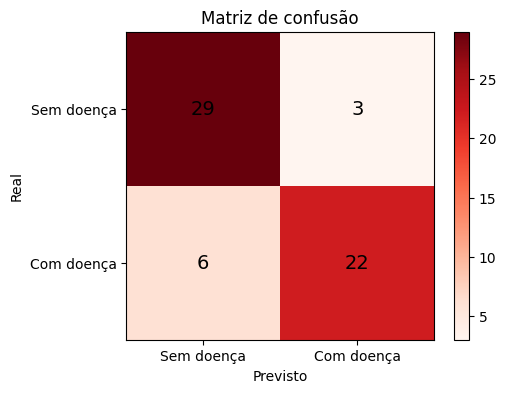

In [27]:
matriz = confusion_matrix(y_teste, previsoes)   # matriz 2x2 de acertos e erros

plt.figure(figsize=(5, 4))
plt.imshow(matriz, cmap="Reds")                             # desenha a matriz com cores
plt.xticks([0, 1], ["Sem doença", "Com doença"])            # nomes no eixo x
plt.yticks([0, 1], ["Sem doença", "Com doença"])            # nomes no eixo y
plt.xlabel("Previsto")
plt.ylabel("Real")
plt.title("Matriz de confusão")

for i in range(2):                  # linhas (real)
    for j in range(2):              # colunas (previsto)
        plt.text(j, i, matriz[i, j], ha="center", va="center", fontsize=14)   # escreve o número na célula

plt.colorbar()                      # barra de cores
plt.show()

### Relatório de classificação

Para cada classe, a precision mostra quantas previsões estavam certas, o recall quantos casos foram encontrados, o f1-score combina os dois e o support é a quantidade de pacientes.

Quando o modelo diz "com doença", acerta 88% das vezes, mas encontra só 79% dos doentes.

In [28]:
print(classification_report(y_teste, previsoes, target_names=["Sem doença", "Com doença"]))   # métricas por classe

              precision    recall  f1-score   support

  Sem doença       0.83      0.91      0.87        32
  Com doença       0.88      0.79      0.83        28

    accuracy                           0.85        60
   macro avg       0.85      0.85      0.85        60
weighted avg       0.85      0.85      0.85        60



## 9. Testando com um paciente

O iloc[[0]] pega o primeiro paciente do teste mantendo o formato de tabela. Ele é padronizado com o mesmo scaler do treino, e o modelo devolve a previsão e a probabilidade, que no KNN é a fração dos 21 vizinhos com doença.

Esse paciente de 41 anos, sem angina e com frequência máxima de 182, foi previsto como sem doença, igual ao valor real.

In [29]:
paciente = X_teste.iloc[[0]]                  # primeiro paciente do teste (como tabela de 1 linha)
paciente_pad = scaler.transform(paciente)     # padroniza com a régua do treino

resultado = modelo.predict(paciente_pad)[0]                  # 0 ou 1
probabilidade = modelo.predict_proba(paciente_pad)[0][1]     # fração de vizinhos com doença

print("Previsão:", "Com doença" if resultado == 1 else "Sem doença")
print("Probabilidade de doença:", round(probabilidade * 100, 1), "%")
print("Valor real:", "Com doença" if y_teste.iloc[0] == 1 else "Sem doença")

Previsão: Sem doença
Probabilidade de doença: 0.0 %
Valor real: Sem doença


## 10. Conclusões

O melhor k foi 21, com 82,2% de acurácia na validação cruzada e 85% no teste. O modelo encontrou 22 dos 28 doentes (recall de 78,6%), com 6 falsos negativos e 3 falsos positivos. Sem padronização a acurácia cai para cerca de 65%, o que mostra que essa etapa é essencial para o KNN.

Os sinais mais ligados à doença foram número de vasos obstruídos, depressão do segmento ST, angina no exercício e frequência cardíaca máxima. A dor do tipo "assintomática" teve 72,5% de doentes, e o colesterol quase não teve relação com a doença.

Como limitações, a base é pequena e de um único hospital, e os falsos negativos mostram que o modelo serve como apoio à triagem, não como diagnóstico. Como próximos passos, daria para usar mais dados, testar outros algoritmos e priorizar o recall.